<a href="https://colab.research.google.com/github/anetpp15/desercion-estudiantil-tfm/blob/main/AvanceDeserEstudiantilOKTFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dataset.csv to dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv('dataset.csv')

In [ ]:
df.info()
df.describe()
print("Shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [ ]:
df.isnull().sum()

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0


In [ ]:
df = df.dropna()

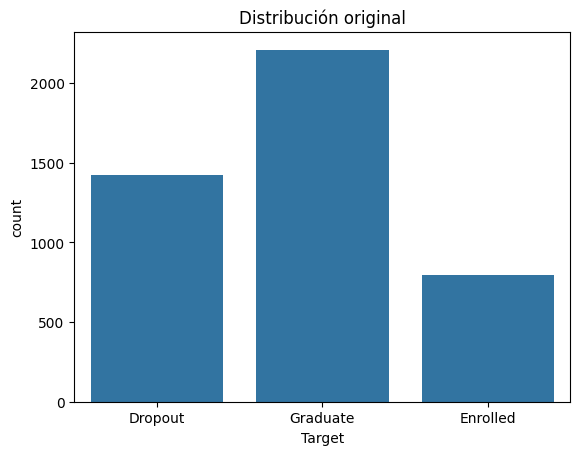

Target
Graduate    0.499322
Dropout     0.321203
Enrolled    0.179476
Name: proportion, dtype: float64


In [ ]:
#Distribución target original
sns.countplot(x='Target', data=df)
plt.title("Distribución original")
plt.show()

print(df['Target'].value_counts(normalize=True))

In [ ]:
#Transformación binaria
df['Target_binary'] = df['Target'].apply(
    lambda x: 1 if x == 'Dropout' else 0
)

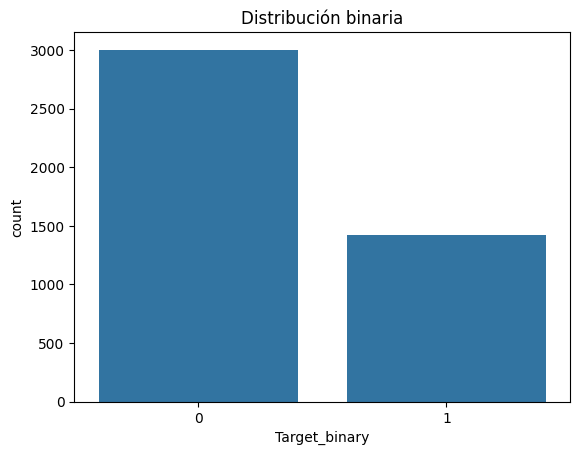

Target_binary
0    0.678797
1    0.321203
Name: proportion, dtype: float64


In [ ]:
sns.countplot(x='Target_binary', data=df)
plt.title("Distribución binaria")
plt.show()

print(df['Target_binary'].value_counts(normalize=True))

In [ ]:
#desbalance de clases
print(df['Target_binary'].value_counts())

Target_binary
0    3003
1    1421
Name: count, dtype: int64


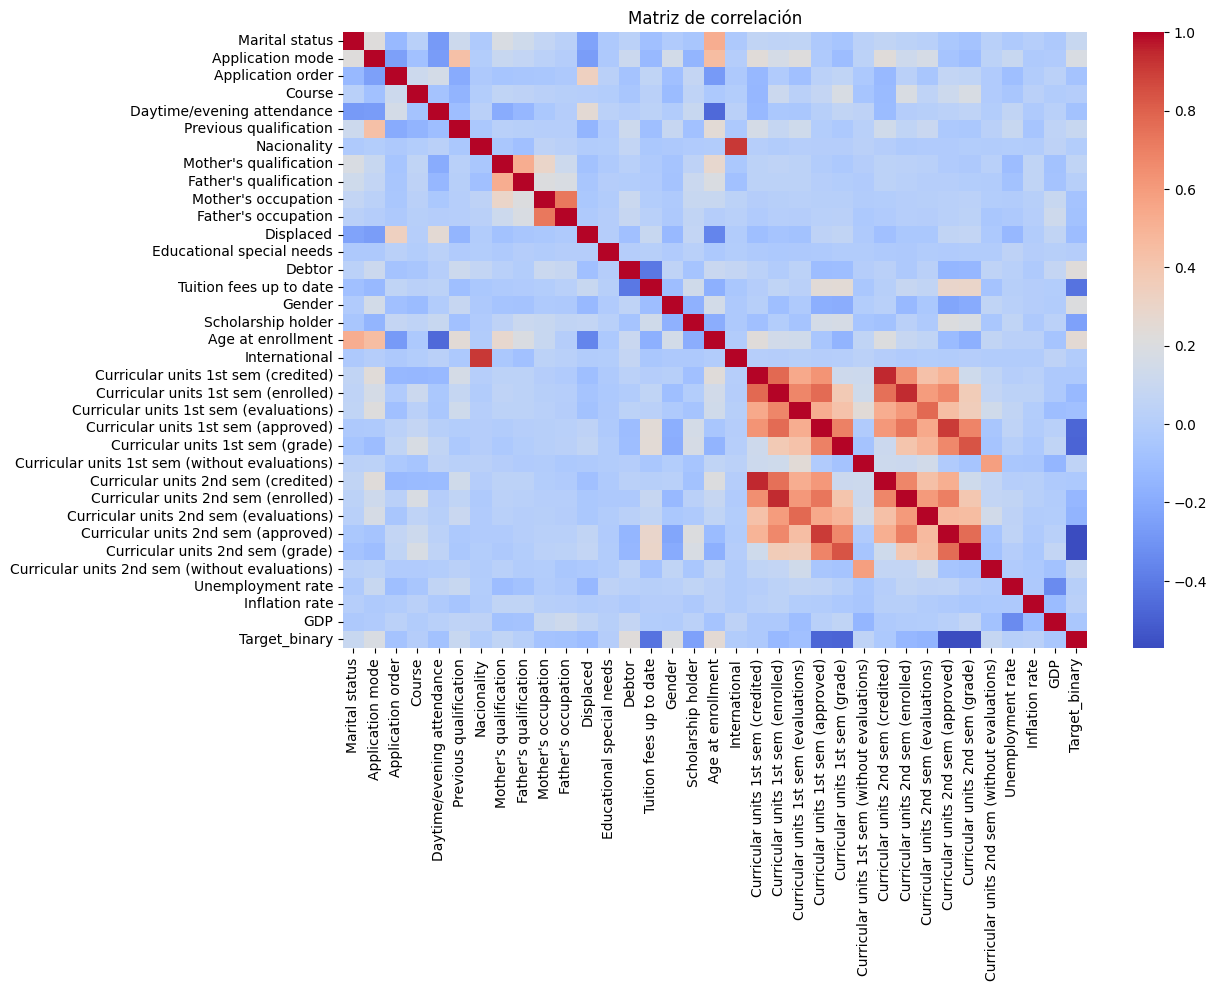

In [ ]:
#Correlación
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm')
plt.title("Matriz de correlación")
plt.show()

In [ ]:
#Identificación de variables más correlacionadas
corr_target = corr['Target_binary'].sort_values(ascending=False)
print(corr_target.head(10))

Target_binary                                     1.000000
Age at enrollment                                 0.254215
Debtor                                            0.229407
Gender                                            0.203983
Application mode                                  0.188908
Marital status                                    0.093712
Previous qualification                            0.091590
Curricular units 2nd sem (without evaluations)    0.079901
Mother's qualification                            0.059499
Curricular units 1st sem (without evaluations)    0.054230
Name: Target_binary, dtype: float64


In [ ]:
#Preprocesamiento
le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

In [ ]:
#Separación
X = df.drop(['Target', 'Target_binary'], axis=1)
y = df['Target_binary']

In [ ]:
#Escalado
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
#Training vs Test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Modelos de Clasificación

In [ ]:
# Regresión Logística balanceada
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [ ]:
# Arboles de decisión realizando el control de overfitting
dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42
)

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

In [ ]:
# Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

## Evaluación de Modelos de Clasificación

In [ ]:
def evaluar_modelo(y_test, y_pred, nombre):
    print(f"\n=== {nombre} ===")

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1-score:", f1_score(y_test, y_pred))

    print("\nReporte completo:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Matriz de Confusión - {nombre}")
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.show()


=== Regresión Logística ===
Accuracy: 0.8745762711864407
Precision: 0.7912457912457912
Recall: 0.8274647887323944
F1-score: 0.8089500860585198

Reporte completo:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91       601
           1       0.79      0.83      0.81       284

    accuracy                           0.87       885
   macro avg       0.85      0.86      0.86       885
weighted avg       0.88      0.87      0.88       885



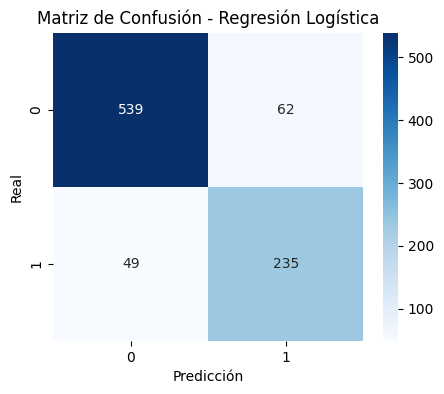


=== Árbol de Decisión ===
Accuracy: 0.847457627118644
Precision: 0.7411003236245954
Recall: 0.8063380281690141
F1-score: 0.7723440134907251

Reporte completo:
              precision    recall  f1-score   support

           0       0.90      0.87      0.89       601
           1       0.74      0.81      0.77       284

    accuracy                           0.85       885
   macro avg       0.82      0.84      0.83       885
weighted avg       0.85      0.85      0.85       885



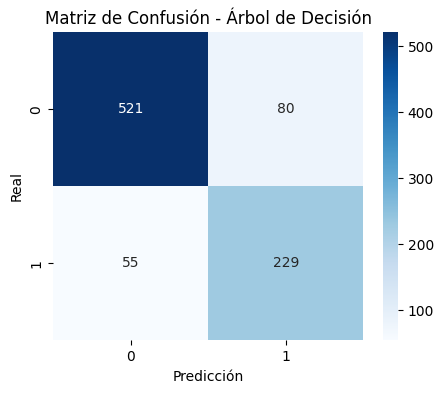


=== Random Forest ===
Accuracy: 0.8779661016949153
Precision: 0.84375
Recall: 0.7605633802816901
F1-score: 0.8

Reporte completo:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91       601
           1       0.84      0.76      0.80       284

    accuracy                           0.88       885
   macro avg       0.87      0.85      0.86       885
weighted avg       0.88      0.88      0.88       885



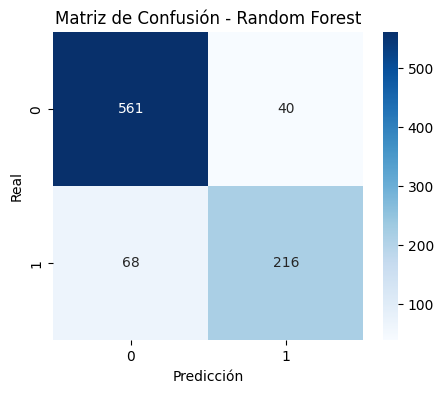

In [ ]:
evaluar_modelo(y_test, y_pred_lr, "Regresión Logística")
evaluar_modelo(y_test, y_pred_dt, "Árbol de Decisión")
evaluar_modelo(y_test, y_pred_rf, "Random Forest")

# ROC‑AUC y G‑Mean





In [ ]:
from sklearn.metrics import roc_auc_score, confusion_matrix
import numpy as np

def calcular_metricas_rocymean(modelo, X_test, y_test):
    # Probabilidades para ROC-AUC
    y_prob = modelo.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_prob)

    # Predicciones para G-Mean
    y_pred = modelo.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    TN, FP, FN, TP = cm.ravel()

    # Sensibilidad (recall de la clase 1)
    sensitivity = TP / (TP + FN)

    # Especificidad (recall de la clase 0)
    specificity = TN / (TN + FP)

    # G-Mean
    gmean = np.sqrt(sensitivity * specificity)

    return roc_auc, gmean


roc_lr, g_lr = calcular_metricas_rocymean(lr, X_test, y_test)
roc_dt, g_dt = calcular_metricas_rocymean(dt, X_test, y_test)
roc_rf, g_rf = calcular_metricas_rocymean(rf, X_test, y_test)

print("=== ROC-AUC y G-Mean ===")
print(f"Regresión Logística -> ROC-AUC: {roc_lr:.4f}, G-Mean: {g_lr:.4f}")
print(f"Árbol de Decisión   -> ROC-AUC: {roc_dt:.4f}, G-Mean: {g_dt:.4f}")
print(f"Random Forest       -> ROC-AUC: {roc_rf:.4f}, G-Mean: {g_rf:.4f}")


=== ROC-AUC y G-Mean ===
Regresión Logística -> ROC-AUC: 0.9290, G-Mean: 0.8615
Árbol de Decisión   -> ROC-AUC: 0.8942, G-Mean: 0.8361
Random Forest       -> ROC-AUC: 0.9295, G-Mean: 0.8426


Validación Cruzada

In [ ]:
for modelo, nombre in zip(
    [lr, dt, rf],
    ["Logística", "Árbol", "Random Forest"]
):
    scores = cross_val_score(
        modelo, X_scaled, y,
        cv=5,
        scoring='f1'
    )

    print(f"{nombre} - F1 promedio: {scores.mean():.4f}")

Logística - F1 promedio: 0.7979
Árbol - F1 promedio: 0.7571
Random Forest - F1 promedio: 0.7930


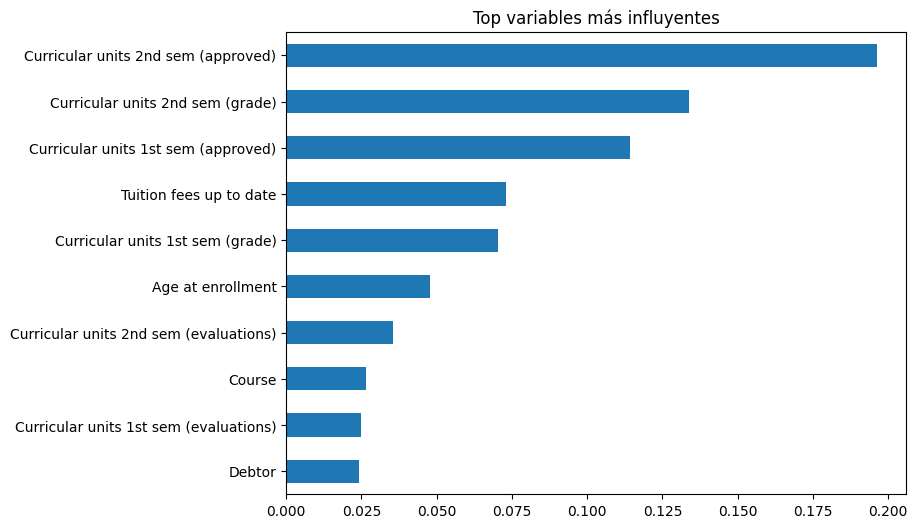

In [ ]:
#Importancia de las variables
importances = rf.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names)\
            .sort_values(ascending=False)

plt.figure(figsize=(8,6))
feat_imp.head(10).plot(kind='barh')
plt.title("Top variables más influyentes")
plt.gca().invert_yaxis()
plt.show()

# Entrenamiento y Evaluación de los modelos XGBoost y CatBoost

In [ ]:
# Modelo XGBoost

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
import numpy as np

# Modelo XGBoost
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

# Entrenamiento
xgb.fit(X_train, y_train)

# Predicciones
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

# Métricas
acc_xgb = accuracy_score(y_test, y_pred_xgb)
prec_xgb = precision_score(y_test, y_pred_xgb)
rec_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_xgb = roc_auc_score(y_test, y_prob_xgb)

# G-Mean
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
TN, FP, FN, TP = cm_xgb.ravel()
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)
gmean_xgb = np.sqrt(sensitivity * specificity)

print("=== XGBoost ===")
print(f"Accuracy: {acc_xgb:.4f}")
print(f"Precision: {prec_xgb:.4f}")
print(f"Recall: {rec_xgb:.4f}")
print(f"F1-score: {f1_xgb:.4f}")
print(f"ROC-AUC: {roc_xgb:.4f}")
print(f"G-Mean: {gmean_xgb:.4f}")
print("Matriz de confusión:\n", cm_xgb)


=== XGBoost ===
Accuracy: 0.8904
Precision: 0.8610
Recall: 0.7852
F1-score: 0.8214
ROC-AUC: 0.9365
G-Mean: 0.8592
Matriz de confusión:
 [[565  36]
 [ 61 223]]


<Figure size 600x600 with 0 Axes>

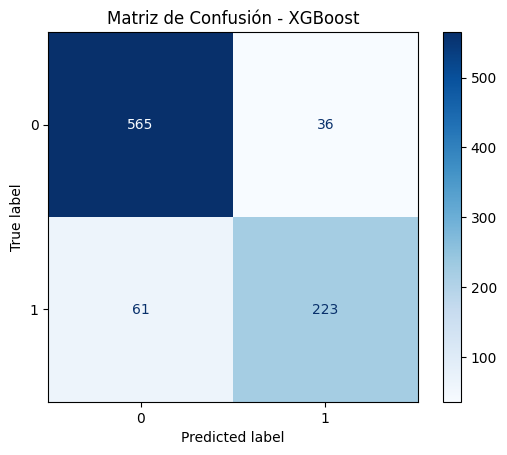

In [ ]:
# Matriz de Confusión XGBoost

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])

plt.figure(figsize=(6,6))
disp.plot(cmap="Blues", values_format='d')
plt.title("Matriz de Confusión - XGBoost")
plt.show()

In [ ]:
# Instalación CatBoost
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


In [ ]:
# CatBoost

from catboost import CatBoostClassifier

# Modelo CatBoost
cat = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=0,
    random_state=42
)

# Entrenamiento
cat.fit(X_train, y_train)

# Predicciones
y_pred_cat = cat.predict(X_test)
y_prob_cat = cat.predict_proba(X_test)[:, 1]

# Métricas
acc_cat = accuracy_score(y_test, y_pred_cat)
prec_cat = precision_score(y_test, y_pred_cat)
rec_cat = recall_score(y_test, y_pred_cat)
f1_cat = f1_score(y_test, y_pred_cat)
roc_cat = roc_auc_score(y_test, y_prob_cat)

# G-Mean
cm_cat = confusion_matrix(y_test, y_pred_cat)
TN, FP, FN, TP = cm_cat.ravel()
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)
gmean_cat = np.sqrt(sensitivity * specificity)

print("=== CatBoost ===")
print(f"Accuracy: {acc_cat:.4f}")
print(f"Precision: {prec_cat:.4f}")
print(f"Recall: {rec_cat:.4f}")
print(f"F1-score: {f1_cat:.4f}")
print(f"ROC-AUC: {roc_cat:.4f}")
print(f"G-Mean: {gmean_cat:.4f}")
print("Matriz de confusión:\n", cm_cat)


=== CatBoost ===
Accuracy: 0.8859
Precision: 0.8588
Recall: 0.7711
F1-score: 0.8126
ROC-AUC: 0.9351
G-Mean: 0.8514
Matriz de confusión:
 [[565  36]
 [ 65 219]]


<Figure size 600x600 with 0 Axes>

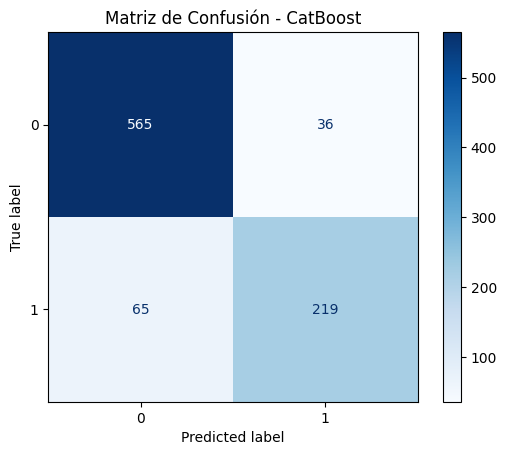

In [ ]:
# Matriz de Confusión CatBoost

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_cat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])

plt.figure(figsize=(6,6))
disp.plot(cmap="Blues", values_format='d')
plt.title("Matriz de Confusión - CatBoost")
plt.show()

# Interpretabilidad SHAP aplicado al mejor modelo (XGBoost)

Generación de gráfico de impacto global de las variables (XGBoost)


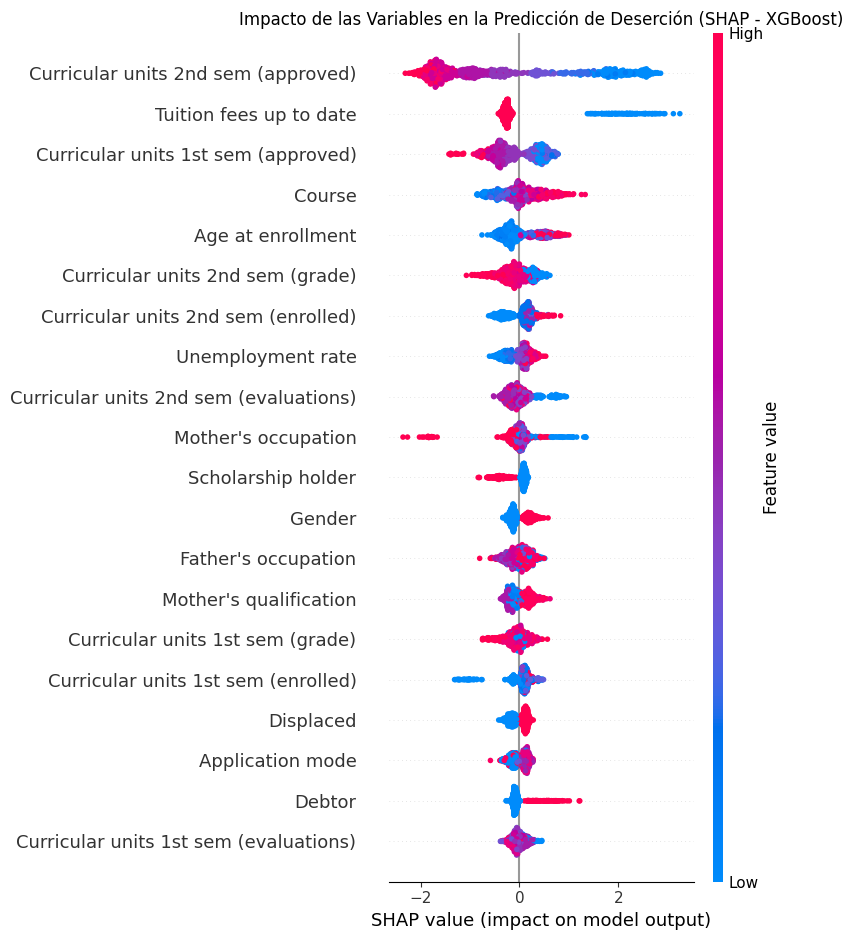

In [ ]:
# Importamos SHAP
!pip install shap
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(xgb)

# Calculamos los valores SHAP para el conjunto de test
shap_values = explainer(X_test)

# Gráfico de resumen
plt.figure(figsize=(10, 6))
print("Generación de gráfico de impacto global de las variables (XGBoost)")

# Utilizamos los datos de X_test para la visualización gráfica
shap.summary_plot(shap_values, X_test, feature_names=X.columns, show=False)

plt.title("Impacto de las Variables en la Predicción de Deserción (SHAP - XGBoost)", fontsize=12)
plt.tight_layout()
plt.show()